# P17C — Dari deteksi ke kepatuhan: aturan di atas keluaran detektor (simulasi)
Detektor objek hanya melaporkan "orang" dan "helm" beserta skor. Penilaian kepatuhan (*pekerja memakai helm*) memerlukan aturan di atas keluaran itu, dan aturan mewarisi seluruh kelemahan sensor. Notebook ini memakai **detektor simulasi**: skor dibangkitkan dari aturan yang mudah dibaca (peluang deteksi naik dengan ukuran pekerja, helm yang dipegang kadang terbaca sebagai helm di kepala). Tidak ada citra dan tidak ada detektor nyata; simulasi hanya memperlihatkan logika evaluasi dan pemilihan ambang. Seed 17019.


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
SEED = 17019
rng = np.random.default_rng(SEED)
print("Simulasi detektor: tidak memakai citra dan tidak mewakili detektor nyata mana pun.")

Simulasi detektor: tidak memakai citra dan tidak mewakili detektor nyata mana pun.


## 1. Pekerja virtual dan keluaran detektor simulasi


In [2]:
N = 4000                                   # pengamatan pekerja (satu pekerja pada satu foto)
tinggi = rng.uniform(40, 300, N)           # tinggi kotak orang (piksel); kecil = jauh dari kamera
pakai = rng.random(N) < 0.90               # 90% memakai helm pada proyek yang cukup tertib
def sig(x): return 1 / (1 + np.exp(-x))
# detektor orang: peluang terdeteksi naik dengan ukuran
p_orang = sig((tinggi - 70) / 25); orang_ok = rng.random(N) < p_orang
skor_orang = np.where(orang_ok, np.clip(rng.normal(0.55 + 0.35 * sig((tinggi - 100) / 40), 0.1), 0.05, 0.99), 0)
# detektor helm: lebih sulit pada objek kecil; helm yang dipegang/tergantung kadang dihitung sebagai helm di kepala
helm_ada = pakai.copy()
p_helm = sig((tinggi - 90) / 30) * 0.97
helm_ok = helm_ada & (rng.random(N) < p_helm)
skor_helm = np.where(helm_ok, np.clip(rng.normal(0.35 + 0.5 * sig((tinggi - 100) / 40), 0.15), 0.05, 0.99), 0)
palsu = (~pakai) & (rng.random(N) < 0.06)  # topi, caping, atau helm di tangan yang dikenali sebagai helm di kepala
skor_helm = np.where(palsu, np.clip(rng.normal(0.45, 0.12), 0.05, 0.95), skor_helm)
df = pd.DataFrame(dict(tinggi=tinggi, pakai=pakai, skor_orang=skor_orang, skor_helm=skor_helm))
print("pekerja:", N, "| tanpa helm sebenarnya:", int((~pakai).sum()), "| orang terdeteksi (skor > 0):", int(orang_ok.sum()))

pekerja: 4000 | tanpa helm sebenarnya: 439 | orang terdeteksi (skor > 0): 3432


## 2. Aturan kepatuhan dan pengaruh ambang
Pekerja dinilai tanpa helm bila orang terdeteksi tetapi helm tidak terdeteksi di area kepalanya.


In [3]:
def aturan(df, th_orang=0.3, th_helm=0.3):
    """Pekerja dinilai 'tanpa helm' bila orang terdeteksi tetapi tidak ada helm di area kepalanya.
    (Pada detektor nyata, 'helm di area kepala' diuji dengan geometri kotak; di sini diwakili skor helm.)"""
    ada_orang = df.skor_orang >= th_orang; ada_helm = df.skor_helm >= th_helm
    return ada_orang & ~ada_helm, ada_orang
def evaluasi(df, th_helm, th_orang=0.3):
    lapor, ada_orang = aturan(df, th_orang, th_helm); nyata = ~df.pakai
    tp = int((lapor & nyata).sum()); fn = int((nyata & ~lapor).sum()); fp = int((lapor & ~nyata).sum())
    return dict(th_helm=th_helm, pelanggaran_tertangkap=tp, pelanggaran_terlewat=fn, alarm_palsu=fp,
                recall=tp / (tp + fn), presisi=tp / max(tp + fp, 1), akurasi=float(((lapor == nyata)).mean()))
tab = pd.DataFrame([evaluasi(df, t) for t in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)]).round(3); print(tab.to_string(index=False))

 th_helm  pelanggaran_tertangkap  pelanggaran_terlewat  alarm_palsu  recall  presisi  akurasi
     0.1                     361                    78          502   0.822    0.418    0.855
     0.2                     361                    78          503   0.822    0.418    0.855
     0.3                     361                    78          513   0.822    0.413    0.852
     0.4                     361                    78          548   0.822    0.397    0.844
     0.5                     388                    51          668   0.884    0.367    0.820
     0.6                     388                    51          889   0.884    0.304    0.765
     0.7                     388                    51         1308   0.884    0.229    0.660
     0.8                     388                    51         1871   0.884    0.172    0.520


## 3. Biaya kesalahan dan pilihan ambang
Menaikkan ambang helm membuat aturan lebih ketat: lebih banyak laporan, pelanggaran terlewat lebih sedikit, alarm palsu lebih banyak. Ambang dipilih dari rasio biaya, bukan dari akurasi.


In [4]:
print("\nRasio biaya (satu pelanggaran terlewat : satu alarm palsu) -> ambang helm yang meminimumkan biaya total")
for rasio in (1, 5, 10, 20):
    gr = np.linspace(0.05, 0.9, 35); biaya = [rasio * evaluasi(df, t)["pelanggaran_terlewat"] + evaluasi(df, t)["alarm_palsu"] for t in gr]
    t_opt = gr[int(np.argmin(biaya))]; e = evaluasi(df, t_opt)
    print(f"rasio {rasio:>2}:1 | ambang {t_opt:.2f} | recall {e['recall']:.3f} | alarm palsu {e['alarm_palsu']} | terlewat {e['pelanggaran_terlewat']}")
t_akur = max(np.linspace(0.05, 0.9, 35), key=lambda t: evaluasi(df, t)["akurasi"]); print("ambang yang memaksimalkan akurasi: %.2f (akurasi %.3f)" % (t_akur, evaluasi(df, t_akur)["akurasi"]))


Rasio biaya (satu pelanggaran terlewat : satu alarm palsu) -> ambang helm yang meminimumkan biaya total
rasio  1:1 | ambang 0.05 | recall 0.822 | alarm palsu 501 | terlewat 78
rasio  5:1 | ambang 0.42 | recall 0.884 | alarm palsu 565 | terlewat 51
rasio 10:1 | ambang 0.42 | recall 0.884 | alarm palsu 565 | terlewat 51
rasio 20:1 | ambang 0.42 | recall 0.884 | alarm palsu 565 | terlewat 51
ambang yang memaksimalkan akurasi: 0.05 (akurasi 0.855)


## 4. Kelemahan sensor menurut ukuran pekerja


In [5]:
df["ukuran"] = pd.cut(df.tinggi, [0, 80, 120, 180, 400], labels=["< 80 px", "80–120 px", "120–180 px", "> 180 px"])
rows = []
for u, g in df.groupby("ukuran", observed=True):
    nyata = ~g.pakai; lapor, ada = aturan(g, 0.3, 0.3)
    rows.append(dict(ukuran=u, n=len(g), tanpa_helm=int(nyata.sum()), orang_terdeteksi=float((g.skor_orang >= 0.3).mean()), pelanggaran_terdeteksi=float((lapor & nyata).sum() / max(nyata.sum(), 1)), alarm_palsu=int((lapor & ~nyata).sum())))
print("\n" + pd.DataFrame(rows).round(3).to_string(index=False))


    ukuran    n  tanpa_helm  orang_terdeteksi  pelanggaran_terdeteksi  alarm_palsu
   < 80 px  586          61             0.399                   0.361          148
 80–120 px  644          59             0.748                   0.780          188
120–180 px  897         101             0.948                   0.911          111
  > 180 px 1873         218             0.996                   0.922           66


## 5. Per bingkai atau per orang?
Satu pekerja tanpa helm pada video 60 bingkai dapat menghasilkan puluhan laporan. Pelaporan yang benar mengagregasi per orang (dengan pelacakan). Di sini ID pekerja dianggap diketahui; pada sistem nyata pelacakan bisa keliru.


In [6]:
M, B = 40, 60                              # 40 pekerja, 60 bingkai
tanpa = rng.random(M) < 0.10               # 4 dari 40 (acak) tanpa helm
tanpa[:2] = True
laporan = np.zeros((M, B), bool)
for i in range(M):
    for f in range(B):
        if tanpa[i]: laporan[i, f] = rng.random() < 0.75             # pelanggaran tertangkap pada 75% bingkai
        else: laporan[i, f] = rng.random() < 0.03                    # alarm palsu 3% bingkai
print("\npekerja tanpa helm sebenarnya:", int(tanpa.sum()), "dari", M)
print("hitung per bingkai (jumlah laporan):", int(laporan.sum()))
for k in (1, 10, 20, 30):
    print(f"hitung per orang, dilaporkan bila >= {k} dari 60 bingkai: {int((laporan.sum(1) >= k).sum())} pekerja"
          f" | tertangkap {int(((laporan.sum(1) >= k) & tanpa).sum())}/{int(tanpa.sum())}, alarm palsu {int(((laporan.sum(1) >= k) & ~tanpa).sum())}")


pekerja tanpa helm sebenarnya: 7 dari 40
hitung per bingkai (jumlah laporan): 356
hitung per orang, dilaporkan bila >= 1 dari 60 bingkai: 35 pekerja | tertangkap 7/7, alarm palsu 28
hitung per orang, dilaporkan bila >= 10 dari 60 bingkai: 7 pekerja | tertangkap 7/7, alarm palsu 0
hitung per orang, dilaporkan bila >= 20 dari 60 bingkai: 7 pekerja | tertangkap 7/7, alarm palsu 0
hitung per orang, dilaporkan bila >= 30 dari 60 bingkai: 7 pekerja | tertangkap 7/7, alarm palsu 0


## 6. Gambar


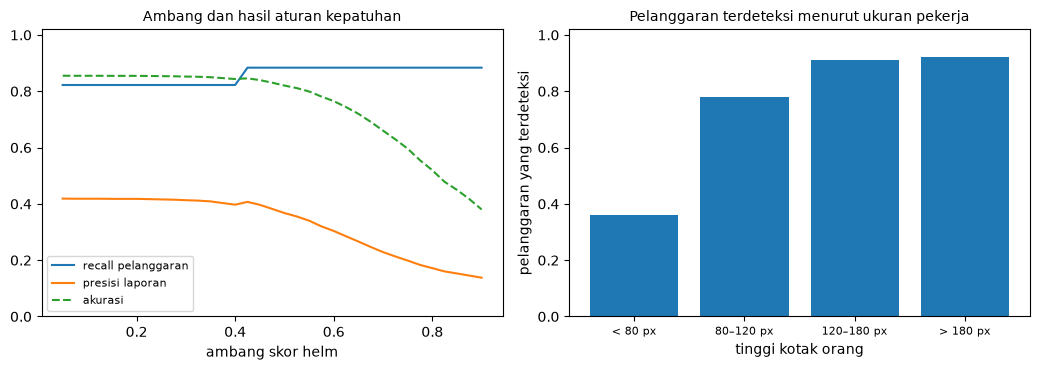

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
ts = np.linspace(0.05, 0.9, 35); ev = [evaluasi(df, t) for t in ts]
ax[0].plot(ts, [e["recall"] for e in ev], label="recall pelanggaran"); ax[0].plot(ts, [e["presisi"] for e in ev], label="presisi laporan"); ax[0].plot(ts, [e["akurasi"] for e in ev], "--", label="akurasi")
ax[0].set_xlabel("ambang skor helm"); ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=8); ax[0].set_title("Ambang dan hasil aturan kepatuhan", fontsize=10)
ax[1].bar(range(len(rows)), [r["pelanggaran_terdeteksi"] for r in rows]); ax[1].set_xticks(range(len(rows))); ax[1].set_xticklabels([str(r["ukuran"]) for r in rows], fontsize=8)
ax[1].set_ylabel("pelanggaran yang terdeteksi"); ax[1].set_ylim(0, 1.02); ax[1].set_xlabel("tinggi kotak orang"); ax[1].set_title("Pelanggaran terdeteksi menurut ukuran pekerja", fontsize=10)
plt.tight_layout(); plt.show()

**Catatan batas.** Semua angka berasal dari generator simulasi; mengubah parameter simulasi mengubah angka. Pesan yang berlaku umum adalah mekanismenya: ambang tidak memperbaiki pekerja yang tidak pernah terdeteksi, dan satuan pelaporan menentukan angka yang tampak.
